<a href="https://colab.research.google.com/github/alexbedoni95-cpu/Analisi-Climatica-UE-e-Modellazione-Predittiva-2035-Progetto-Finale-EEA-/blob/main/Progetto_finale_aulab_7_e_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Predizione delle Emissioni di Gas Serra Senza CO2 in Italia

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, MinMaxScaler
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# Carica i dataset delle emissioni di gas serra e CO2
df_ghg = pd.read_csv('/content/GHG_Emissions.csv')
df_co2 = pd.read_csv('/content/CO2_Emissions.csv')

print("Dataset GHG_Emissions.csv caricato:")
display(df_ghg.head())
print("\nDataset CO2_Emissions.csv caricato:")
display(df_co2.head())

Dataset GHG_Emissions.csv caricato:


,Country,1990,1991,1992,1993,1994,1995,1996,1997,1998,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,Afghanistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Albania,4341.63,6486.66,4581.28,4588.0,4906.36,4883.76,4998.58,5107.07,5830.67,...,8125.69,8125.7,8125.7,8125.7,8125.69,9921.61,5743.87,6580.85,10417.69,10031.01
2,Algeria,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Angola,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Antigua and Barbuda,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Dataset CO2_Emissions.csv caricato:


,Country,1990,1991,1992,1993,1994,1995,1996,1997,1998,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,Afghanistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Albania,3101.66,5166.7,3311.06,3235.47,3500.49,3477.42,3341.56,3426.64,4139.06,...,5942.57,5942.57,5942.56,5942.57,5942.56,8715.51,5280.94,5239.62,9151.29,8798.25
2,Algeria,NaN,NaN,NaN,NaN,63705.00,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Angola,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Antigua and Barbuda,288.14,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Pre-elaborazione e Creazione della Variabile Target

In [ ]:
# Filtra i dati GHG per l'Italia e trasforma in formato 'long'
df_italy_ghg_melted = df_ghg[df_ghg['Country'] == 'Italy'].melt(
    id_vars=['Country'], var_name='year', value_name='Total GHG Emissions'
)
df_italy_ghg_melted['year'] = pd.to_numeric(df_italy_ghg_melted['year'], errors='coerce')
df_italy_ghg_filtered = df_italy_ghg_melted.dropna(subset=['year'])[
    (df_italy_ghg_melted['year'] >= 1990) & (df_italy_ghg_melted['year'] <= 2023)
].copy()
df_italy_ghg_trend = df_italy_ghg_filtered.groupby('year')['Total GHG Emissions'].sum().reset_index()

# Filtra i dati CO2 per l'Italia e trasforma in formato 'long'
df_italy_co2_melted = df_co2[df_co2['Country'] == 'Italy'].melt(
    id_vars=['Country'], var_name='year', value_name='CO2 Emissions'
)
df_italy_co2_melted['year'] = pd.to_numeric(df_italy_co2_melted['year'], errors='coerce')
df_italy_co2_filtered = df_italy_co2_melted.dropna(subset=['year'])[
    (df_italy_co2_melted['year'] >= 1990) & (df_italy_co2_melted['year'] <= 2023)
].copy()
df_italy_co2_trend = df_italy_co2_filtered.groupby('year')['CO2 Emissions'].sum().reset_index()

# Unisci i dati delle emissioni totali di GHG e delle emissioni di CO2
df_combined = pd.merge(df_italy_ghg_trend, df_italy_co2_trend, on='year', how='inner')

# Calcola le emissioni di gas serra senza CO2
df_combined['GHG Emissions without CO2'] = df_combined['Total GHG Emissions'] - df_combined['CO2 Emissions']

display(df_combined.head())

,year,Total GHG Emissions,CO2 Emissions,GHG Emissions without CO2
0,1990,516051.74,438008.80,78042.94
1,1991,517107.00,437538.60,79568.40
2,1992,516117.31,437829.80,78287.51
3,1993,509104.90,430179.96,78924.94
4,1994,503368.55,424581.72,78786.83


### Creazione delle Feature Lag e Divisione dei Dati

In [ ]:
# Assicuriamoci di avere un dataframe pulito per le previsioni
df_prediction = df_combined[['year', 'GHG Emissions without CO2']].copy()

# Creazione di variabili lag (ritardate) per migliorare la previsione di serie temporali
# Useremo le emissioni degli anni precedenti come feature
for i in range(1, 3): # Creiamo lag di 1 e 2 anni
    df_prediction[f'GHG_lag_{i}'] = df_prediction['GHG Emissions without CO2'].shift(i)

# Rimuoviamo le righe con valori NaN risultanti dalle operazioni di shift
df_prediction.dropna(inplace=True)

display(df_prediction.head())

# Dividiamo i dati in training e test set
# Useremo i dati fino al 2020 per l'addestramento e gli anni successivi per il test

X = df_prediction.drop('GHG Emissions without CO2', axis=1)
y = df_prediction['GHG Emissions without CO2']

# Per i modelli tradizionali (Linear e Polynomial Regression)
# Suddividiamo basandoci sull'anno per mantenere l'ordine temporale
X_train_classic = X[X['year'] <= 2020]
y_train_classic = y[X['year'] <= 2020]
X_test_classic = X[X['year'] > 2020]
y_test_classic = y[X['year'] > 2020]

# Per l'LSTM, escludiamo la colonna 'year' dalle feature X
X_lstm = df_prediction.drop(['year', 'GHG Emissions without CO2'], axis=1)
y_lstm = df_prediction['GHG Emissions without CO2']

X_train_lstm = X_lstm[X['year'] <= 2020]
y_train_lstm = y_lstm[X['year'] <= 2020]
X_test_lstm = X_lstm[X['year'] > 2020]
y_test_lstm = y_lstm[X['year'] > 2020]

print(f"Dimensioni set di addestramento (classico): {X_train_classic.shape}, {y_train_classic.shape}")
print(f"Dimensioni set di test (classico): {X_test_classic.shape}, {y_test_classic.shape}")
print(f"Dimensioni set di addestramento (LSTM): {X_train_lstm.shape}, {y_train_lstm.shape}")
print(f"Dimensioni set di test (LSTM): {X_test_lstm.shape}, {y_test_lstm.shape}")

,year,GHG Emissions without CO2,GHG_lag_1,GHG_lag_2
2,1992,78287.51,79568.40,78042.94
3,1993,78924.94,78287.51,79568.40
4,1994,78786.83,78924.94,78287.51
5,1995,81102.57,78786.83,78924.94
6,1996,81260.82,81102.57,78786.83


Dimensioni set di addestramento (classico): (29, 3), (29,)
Dimensioni set di test (classico): (3, 3), (3,)
Dimensioni set di addestramento (LSTM): (29, 2), (29,)
Dimensioni set di test (LSTM): (3, 2), (3,)


### 1. Regressione Lineare

Regressione Lineare - RMSE: 39595.76
Regressione Lineare - R-squared: -22.44


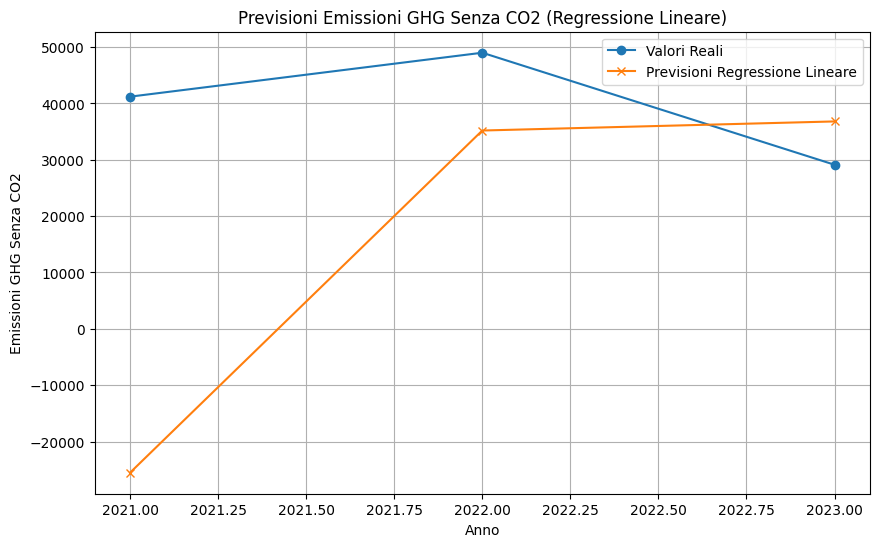

In [ ]:
# Inizializza e addestra il modello di Regressione Lineare
model_linear = LinearRegression()
model_linear.fit(X_train_classic, y_train_classic)

# Effettua previsioni sul set di test
y_pred_linear = model_linear.predict(X_test_classic)

# Valuta il modello
rmse_linear = np.sqrt(mean_squared_error(y_test_classic, y_pred_linear))
r2_linear = r2_score(y_test_classic, y_pred_linear)

print(f"Regressione Lineare - RMSE: {rmse_linear:.2f}")
print(f"Regressione Lineare - R-squared: {r2_linear:.2f}")

# Visualizza i risultati
plt.figure(figsize=(10, 6))
plt.plot(X_test_classic['year'], y_test_classic, label='Valori Reali', marker='o')
plt.plot(X_test_classic['year'], y_pred_linear, label='Previsioni Regressione Lineare', marker='x')
plt.title('Previsioni Emissioni GHG Senza CO2 (Regressione Lineare)')
plt.xlabel('Anno')
plt.ylabel('Emissioni GHG Senza CO2')
plt.legend()
plt.grid(True)
plt.show()

### 2. Regressione Polinomiale

Regressione Polinomiale - RMSE: 200981.22
Regressione Polinomiale - R-squared: -602.86


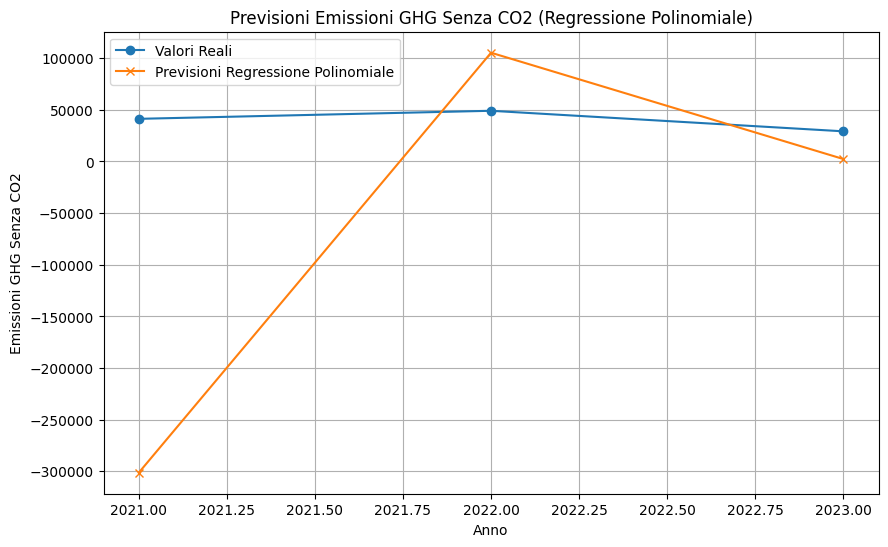

In [ ]:
# Creazione di feature polinomiali
poly_features = PolynomialFeatures(degree=2) # Puoi modificare il grado del polinomio
X_train_poly = poly_features.fit_transform(X_train_classic.drop('year', axis=1))
X_test_poly = poly_features.transform(X_test_classic.drop('year', axis=1))

# Inizializza e addestra il modello di Regressione Lineare sui dati polinomiali
model_poly = LinearRegression()
model_poly.fit(X_train_poly, y_train_classic)

# Effettua previsioni sul set di test
y_pred_poly = model_poly.predict(X_test_poly)

# Valuta il modello
rmse_poly = np.sqrt(mean_squared_error(y_test_classic, y_pred_poly))
r2_poly = r2_score(y_test_classic, y_pred_poly)

print(f"Regressione Polinomiale - RMSE: {rmse_poly:.2f}")
print(f"Regressione Polinomiale - R-squared: {r2_poly:.2f}")

# Visualizza i risultati
plt.figure(figsize=(10, 6))
plt.plot(X_test_classic['year'], y_test_classic, label='Valori Reali', marker='o')
plt.plot(X_test_classic['year'], y_pred_poly, label='Previsioni Regressione Polinomiale', marker='x')
plt.title('Previsioni Emissioni GHG Senza CO2 (Regressione Polinomiale)')
plt.xlabel('Anno')
plt.ylabel('Emissioni GHG Senza CO2')
plt.legend()
plt.grid(True)
plt.show()

### 3. Modello LSTM (Long Short-Term Memory)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 224ms/step
LSTM - RMSE: 41402.75
LSTM - R-squared: -24.63


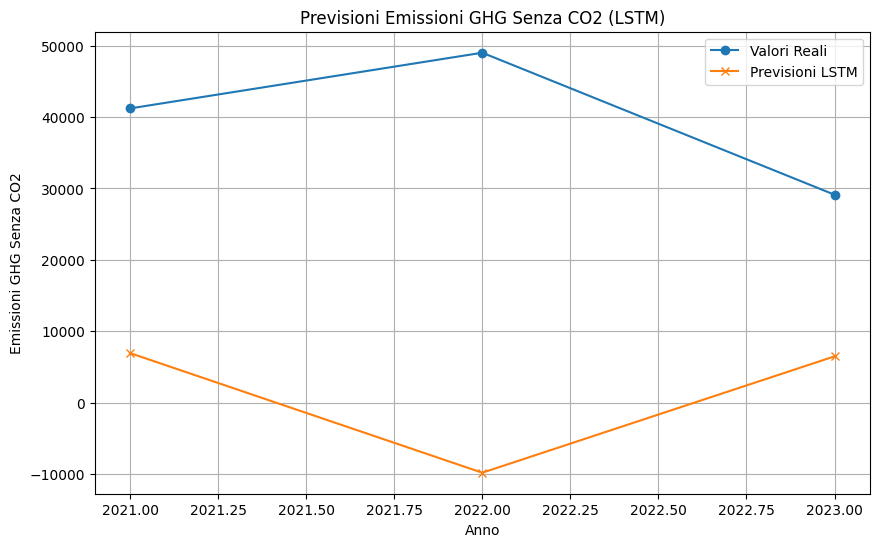

In [ ]:
# Normalizzazione dei dati per LSTM
scaler_X = MinMaxScaler(feature_range=(0, 1))
scaler_y = MinMaxScaler(feature_range=(0, 1))

X_train_scaled = scaler_X.fit_transform(X_train_lstm)
y_train_scaled = scaler_y.fit_transform(y_train_lstm.values.reshape(-1, 1))
X_test_scaled = scaler_X.transform(X_test_lstm)
y_test_scaled = scaler_y.transform(y_test_lstm.values.reshape(-1, 1))

# Reshape per LSTM [samples, timesteps, features]
# Abbiamo 2 feature (GHG_lag_1, GHG_lag_2) e 1 timestep per ogni campione
X_train_lstm_reshaped = X_train_scaled.reshape(X_train_scaled.shape[0], 1, X_train_scaled.shape[1])
X_test_lstm_reshaped = X_test_scaled.reshape(X_test_scaled.shape[0], 1, X_test_scaled.shape[1])

# Costruzione del modello LSTM
model_lstm = Sequential()
model_lstm.add(LSTM(50, activation='relu', input_shape=(X_train_lstm_reshaped.shape[1], X_train_lstm_reshaped.shape[2])))
model_lstm.add(Dense(1))
model_lstm.compile(optimizer='adam', loss='mse')

# Addestramento del modello
history = model_lstm.fit(X_train_lstm_reshaped, y_train_scaled, epochs=50, batch_size=1, verbose=0)

# Effettua previsioni sul set di test
y_pred_lstm_scaled = model_lstm.predict(X_test_lstm_reshaped)

# Inverti la scalatura per ottenere i valori originali
y_pred_lstm = scaler_y.inverse_transform(y_pred_lstm_scaled)
y_test_actual = scaler_y.inverse_transform(y_test_scaled)

# Valuta il modello
rmse_lstm = np.sqrt(mean_squared_error(y_test_actual, y_pred_lstm))
r2_lstm = r2_score(y_test_actual, y_pred_lstm)

print(f"LSTM - RMSE: {rmse_lstm:.2f}")
print(f"LSTM - R-squared: {r2_lstm:.2f}")

# Visualizza i risultati
plt.figure(figsize=(10, 6))
plt.plot(X_test_classic['year'], y_test_actual, label='Valori Reali', marker='o')
plt.plot(X_test_classic['year'], y_pred_lstm, label='Previsioni LSTM', marker='x')
plt.title('Previsioni Emissioni GHG Senza CO2 (LSTM)')
plt.xlabel('Anno')
plt.ylabel('Emissioni GHG Senza CO2')
plt.legend()
plt.grid(True)
plt.show()